# Lasso regression | optimisation, generalisation and finite-sample bounds

**Research question.** How do sparsity and predictor correlation affect Lasso's prediction risk, support recovery and computational behaviour?

The workflow is to define the objective, implement and verify the solver, evaluate held-out prediction, then isolate the assumptions behind the finite-sample bounds. The random-design experiment compares models on fresh observations. The fixed-design experiments condition on the realised design and redraw only the noise.

**Run.** Open in Jupyter and run all cells in order with a Python 3 kernel containing NumPy, Matplotlib and scikit-learn. For a new environment, run `python -m pip install jupyter numpy matplotlib scikit-learn` in a terminal. No data downloads are needed. The supplied PDFs are identified in the references at the end.

The experiments use fixed seeds. Run the cells in order to reproduce the figures and tables.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"

from math import erfc, sqrt
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso

## 0. Introducing the Lasso

Let us recall the general statistical learning problem at hand:

Suppose we have $(\mathbf{x}_i\times{y_i})_{i=1}^n\overset{iid}{\sim}\overset{n}{\underset{i=1}{\bigotimes}}\,P(\mathbb{R}^p\times{\mathbb{R}})$ training data. Consider using a MSE error loss function $l:\mathbb{R}^p\times{\mathbb{R}}\times{\mathcal{H}}\rightarrow{\mathbb{R}^{\geq{0}}}, (X,Y,f)\mapsto{||Y-f(X)||_2^2}$ where $\mathcal{H}$ is some suitably large hypothesis class of functions. We wish to find:
$$f_{\mathcal{H}}^*=\underset{f\in{\mathcal{H}}}{arg\,min}\:R(f)\in{\mathcal{H}}$$
where $R(f)=\mathbb{E}_{X\times{Y}\sim{P}}\big(l(X,Y,f)\big)$ is the population risk. To minimise $R$ over $f\in{\mathcal{H}}$, by conditioning, is to minimise the integral:
$$\int_{\mathbb{R}^p}\int_{\mathbb{R}}||Y-f(X)||_2^2d\mathbb{P}_{Y|X}d\mathbb{P}_X=\mathbb{E}_{X\sim{\mathbb{P}_X}}\mathbb{E}_{Y|X\sim{\mathbb{P}_{Y|X}}}\big(||Y-f(X)||_2^2\big|X=x)$$

Hence, writing $f(x)=f_x$ for each $x\in{\mathbb{R}^p}$, it suffices to $R(f)$ by minimising the following conditional expectation, pointwise in $x$
$$\mathbb{E}_{Y|X\sim{\mathbb{P}_{Y|X}}}\big(||Y-f_x||_2^2\big|X=x)$$
Since this is a convex and differentiable function in $f_x\in{\mathbb{R}}$, we can differentiate with respect to $f_x$ to find the global minima as the conditional expectation:
$$f(x)=\mathbb{E}_{Y|X\sim{\mathbb{P}_{Y|X}}}\big(Y|X=x\big)$$
So, the regression function $f$ is minimised by outputting the mean of $Y$ as a random variable conditioned against $X=x$.

Now, when performing linear regression for our training data, we make the hypothesis that our MSE population risk minimiser, namely the coniditional mean, takes a linear form
$$f_{\mathcal{H}}^*(X)=\mathbb{E}_{Y|X\sim{\mathbb{P}_{Y|X}}}\big(Y|X=x\big)=X\beta + \epsilon$$
where $\epsilon\sim{\mathcal{N}(0,\sigma)}$, $\beta\in{\mathbb{R}^p}$ and $X=(\mathbf{x}_1,...\mathbf{x}_n)^T\in{\mathbb{R}^{n\times{p}}}$. Where we re-initialise $\mathbf{x}_i=(1,x_{i,j})_{j=1}^p$ and $p=p+1$, so that $\beta_0$ is the intercept.

## 1. Empirical risk, sparsity and the Lasso

We want to minimise the **empirical risk** of our linear model $X\beta$ under mean squared error (MSE), with an added $\ell_1$ penalty. Let us build that objective from the training pairs in Section 0.

### 1.1 From training pairs to empirical MSE

For each training observation $i$, we have a pair $(\mathbf x_i,y_i)$, where $\mathbf x_i=(x_{i1},\dots,x_{ip})^\top\in\mathbb R^p$ and $y_i\in\mathbb R$. A **predictor** is an input variable used to make a prediction. For example, when predicting house prices, floor area and number of bedrooms can be predictors. The **response** is the quantity we want to predict, such as the observed sale price $y_i$.

For now write $X^{\rm raw}$ for the $n\times p$ matrix of the original predictors. Row $i$ is $\mathbf x_i^\top$, column $j$ contains all $n$ observations of predictor $j$, and $y^{\rm raw}=(y_1,\ldots,y_n)^\top$ collects the responses. As in Section 0, we can put a column of ones in the design matrix to represent the intercept. Here we write the intercept separately as $a\in\mathbb R$, so our fitted value at observation $i$ is
$$
\hat y_i(a,b)=a+\mathbf x_i^\top b
=a+\sum_{j=1}^p x_{ij}b_j,
\qquad b\in\mathbb R^p.
$$
The **residual** at this observation is $r_i(a,b)=y_i-\hat y_i(a,b)$. For example, if the observed response is $10$ and the prediction is $8$, the residual is $2$. A residual is computed from a chosen model and the observed data. In the statistical model $Y=a^0+X^\top b^0+\epsilon$ for one observation, the noise $\epsilon$ is the deviation from the true conditional mean, which we generally cannot observe directly.

Section 0 defined population risk by averaging over the unknown distribution of $(X,Y)$. Empirical risk averages the same squared loss over the $n$ training observations:
$$
\widehat R_n(a,b)
=\frac1n\sum_{i=1}^n \big(y_i-a-\mathbf x_i^\top b\big)^2
=\frac1n\|y^{\rm raw}-a\mathbf 1-X^{\rm raw}b\|_2^2.
$$
Ordinary least squares (OLS) chooses $(a,b)$ to minimise $\widehat R_n(a,b)$.

### 1.2 Why add the Lasso penalty?

In Shah Chapter 2, Section 2.1, the starting assumption is that there may be $p$ measured predictors, while only a small number enter the true linear mean. If $b^0$ is the true slope vector, define
$$
S=\{j:b^0_j\ne0\},\qquad s=|S|.
$$
We call $b^0$ **sparse** when $s\ll p$. In a fixed, full-column-rank design with noise variance $\sigma^2$, Shah compares the OLS mean squared prediction error for the true mean at the training design, $\sigma^2p/n$, with $\sigma^2s/n$ for a fit that already knows which $s$ columns to use. The comparison explains the potential benefit of using fewer predictors. In practice, $S$ is unknown.

Shah Section 2.2, equation (2.1), introduces Lasso by adding the $\ell_1$ norm of the slopes, $\|b\|_1=\sum_{j=1}^p |b_j|$. Using the predictor units in which we intend to fit, the objective is
$$
\min_{a,b}\left\{
\frac{1}{2n}\sum_{i=1}^n\big(y_i-a-\mathbf x_i^\top b\big)^2
+\lambda\sum_{j=1}^p|b_j|
\right\}.
$$
The first term is half the empirical MSE. The factor $1/2$ cancels the $2$ when we differentiate. The second term charges $\lambda|b_j|$ for using slope $j$. The intercept $a$ is free to set the overall level of the predictions. At $\lambda=0$ the criterion reduces to least squares. For $\lambda>0$, Lasso can shrink a fitted slope all the way to zero. A zero slope means its predictor contributes nothing to the fitted linear mean. The KKT conditions below show precisely when zero is allowed.

### 1.3 Centre first, then scale

Before fitting, we centre and scale each **predictor column** using its own training mean and training standard deviation. For predictor $j$, compute
$$
m_j=\frac1n\sum_{i=1}^n x_{ij},
\qquad
d_j=\sqrt{\frac1n\sum_{i=1}^n(x_{ij}-m_j)^2},
\qquad
z_{ij}=\frac{x_{ij}-m_j}{d_j}.
$$
**Centring** is subtracting $m_j$. It moves the column's mean to zero. **Scaling** is dividing the centred values by $d_j$. It expresses them in units of one training standard deviation. For example, if training floor areas have mean $80$ and standard deviation $20$ square metres, an area of $110$ is centred to $30$ and then scaled to $1.5$. The same training values $80$ and $20$ are used for validation and test rows. A constant predictor becomes a column of zeros after centring, and the code uses a divisor of $1$ for that column.

Scaling matters because the Lasso penalty acts on coefficient magnitudes. Measuring floor area in square centimetres would make the raw coefficient much smaller than measuring it in square metres, even for the same predictions. We therefore penalise slopes in standardised predictor units.

Let $z_i^\top$ denote row $i$ of the standardised design and let $\beta$ be the vector of slopes in these units. For any fixed $\beta$, the intercept in the model $a+z_i^\top\beta$ minimises the squared error when
$$
0=-\frac1n\sum_{i=1}^n(y_i-a-z_i^\top\beta)
\quad\Longrightarrow\quad
a=\bar y-\bar z^\top\beta=\bar y,
$$
because each standardised column has mean zero. Thus we subtract the training mean from the response and fit the slopes to $y_i-\bar y$. We leave the response in its original units. To predict a new response, standardise its predictors using the training statistics and add $\bar y$ back to the model output.

For the rest of the notebook, $X$ denotes the centred, scaled design and $y$ denotes the centred response. The slope-only problem is
$$
\hat\beta_\lambda\in\operatorname*{arg\,min}_{\beta\in\mathbb R^p}
Q_\lambda(\beta),
\qquad
Q_\lambda(\beta)=\underbrace{\frac1{2n}\|y-X\beta\|_2^2}_{\text{half the empirical MSE}}
+\underbrace{\lambda\|\beta\|_1}_{\text{Lasso penalty}}.
$$
This is the centred form of Shah Section 2.2, equation (2.2). ESL Chapter 3, Section 3.4.2, also gives a constrained formulation using an $\ell_1$ budget.

### 1.4 Convex optimality and the KKT conditions

The squared-error term and the $\ell_1$ penalty are both convex, so their sum is convex. The loss is differentiable in $\beta$, with gradient
$$
-\frac{X^\top(y-X\beta)}n.
$$
The penalty involves $|t|$, whose slope is $-1$ for $t<0$ and $+1$ for $t>0$. At $t=0$ there is a corner. A **subgradient** at a point is a slope of a line through that point that stays below the function. At zero, $|u|\ge vu$ for every $u\in\mathbb R$ exactly when $v\in[-1,1]$. Thus
$$
\partial |t|=
\begin{cases}
\{-1\}, & t<0,\\
[-1,1], & t=0,\\
\{1\}, & t>0.
\end{cases}
$$
The **convex optimality condition** is
$$
\hat\beta\text{ minimises }Q_\lambda
\quad\Longleftrightarrow\quad
0\in\partial Q_\lambda(\hat\beta).
$$
The zero subgradient gives a horizontal supporting plane, so every other point has objective value at least $Q_\lambda(\hat\beta)$. See Shah Section 2.2.3, Propositions 19 and 20.

To apply this condition, let $r=y-X\hat\beta$ be the fitted residual vector and $X_{\cdot j}$ be column $j$ of $X$. Set $g_j=X_{\cdot j}^\top r/n$. Then $-g_j$ is the derivative of the squared-error term with respect to slope $j$. We need a subgradient $v_j$ of the absolute-value term such that $-g_j+\lambda v_j=0$. Substituting the three cases above gives the **Lasso KKT conditions** in Shah Section 2.2.4:
$$
\begin{aligned}
\hat\beta_j>0 &\ \Longrightarrow\ g_j=\lambda,\\
\hat\beta_j<0 &\ \Longrightarrow\ g_j=-\lambda,\\
\hat\beta_j=0 &\ \Longrightarrow\ |g_j|\le\lambda.
\end{aligned}
$$
At a zero slope, the penalty can balance any loss derivative between $-\lambda$ and $\lambda$. For example, if $\lambda=0.3$ and $g_j=0.1$, the choice $v_j=g_j/\lambda=1/3$ is allowed at zero and cancels the derivative. This is how the $\ell_1$ penalty can produce exact zeros. At a nonzero slope the penalty has a single possible derivative, so the score must equal the corresponding endpoint.

A candidate vector solves the Lasso problem if it satisfies these conditions for every coordinate. For the all-zero vector, $r=y$, so the smallest penalty at which all slopes can be zero is $\lambda_{\max}=\|X^\top y/n\|_\infty$. The next code cell evaluates the objective, computes the largest KKT violation, and defines the centring and scaling used in the experiments.

In [2]:
def objective(X, y, beta, lam):
    return 0.5 * np.mean((y - X @ beta)**2) + lam * np.sum(np.abs(beta))


def kkt_error(X, y, beta, lam):
    score = X.T @ (y - X @ beta) / len(y)
    error = np.maximum(np.abs(score) - lam, 0)
    active = beta != 0
    error[active] = np.abs(score[active] - lam * np.sign(beta[active]))
    return error.max()


def standardise(X):
    mean = X.mean(axis=0)
    scale = X.std(axis=0)
    scale[scale == 0] = 1
    return (X - mean) / scale, mean, scale


def lambda_max(X, y):
    return np.max(np.abs(X.T @ y)) / len(y)

## 2. Derive and implement cyclic coordinate descent

Hold all coordinates except $j$ fixed. With full residual $r=y-X\beta$, the partial residual is $r_j=r+x_j\beta_j$. Set $h_j=x_j^\top x_j/n$ and $z_j=x_j^\top r_j/n$. The part of the objective that depends on the candidate coordinate $t$ is
$$\frac{h_j}{2}t^2-z_jt+\lambda|t|.$$
For $t>0$, stationarity gives $(z_j-\lambda)/h_j$ and requires $z_j>\lambda$. For $t<0$, it gives $(z_j+\lambda)/h_j$ and requires $z_j<-\lambda$. At zero the subgradient contains zero exactly when $|z_j|\le\lambda$. Thus the update is
$$t=\frac{\operatorname{sgn}(z_j)(|z_j|-\lambda)_+}{h_j},\qquad r\leftarrow r-x_j(t-\beta_j).$$
If $h_j=0$, the coordinate minimiser is zero. The implementation cycles through coordinates, updates the residual after each coordinate change, and checks all KKT conditions after every sweep. Exact coordinate minimisation decreases the objective. For $\lambda>0$, sublevel sets are compact because the penalty is coercive. Shah §2.2.10 discusses convergence for convex differentiable loss plus separable convex penalties. ESL §3.8.6, eqs. (3.83)–(3.84), gives the equivalent soft-threshold update in its unit-norm convention. Here the loss scaling and column convention match Shah and scikit-learn.

In [3]:
def soft_threshold(z, lam):
    return max(z - lam, 0) + min(z + lam, 0)


def coordinate_descent(X, y, lam, start=None, tol=1e-8):
    n, p = X.shape
    X = np.asfortranarray(X)
    beta = np.zeros(p) if start is None else start.copy()
    h = np.mean(X**2, axis=0)
    beta[h == 0] = 0
    residual = y - X @ beta
    errors = [kkt_error(X, y, beta, lam)]

    if errors[-1] <= tol:
        return beta, errors

    for sweep in range(10_000):
        for j in range(p):
            if h[j] == 0:
                continue
            x = X[:, j]
            z = x @ residual / n + h[j] * beta[j]
            new_beta = soft_threshold(z, lam) / h[j]
            if new_beta != beta[j]:
                residual -= x * (new_beta - beta[j])
                beta[j] = new_beta
        errors.append(kkt_error(X, y, beta, lam))
        if errors[-1] <= tol:
            return beta, errors

    raise RuntimeError("Coordinate descent did not reach the KKT tolerance")

### A small example

Generate two predictors and put a signal only in the first. For each fitted coefficient, print its score $g_j$ alongside $\lambda$. Check the equality for the active coefficient and the inequality for the zero coefficient. The scatter plot compares observed responses with fitted values on this training sample.

Coefficients: [1.75474642 0.        ]
KKT scores: [0.3       0.0652061]
Lambda: 0.3


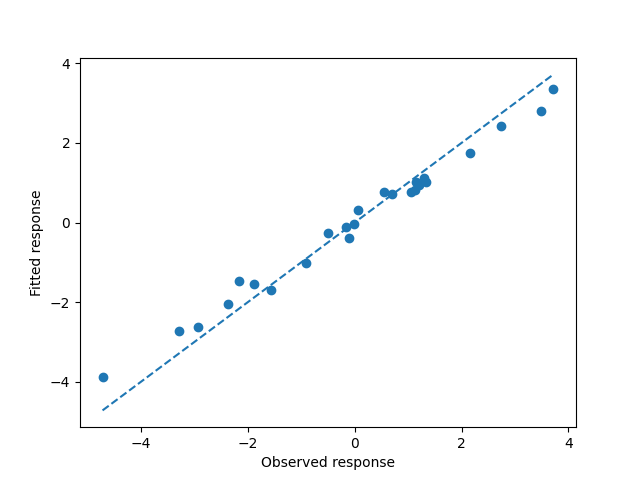

In [4]:
rng = np.random.default_rng(7)
X, _, _ = standardise(rng.normal(size=(25, 2)))
y = 2 * X[:, 0] + rng.normal(scale=0.25, size=25)
y -= y.mean()

lam = 0.3
beta, errors = coordinate_descent(X, y, lam)
print("Coefficients:", beta)
print("KKT scores:", X.T @ (y - X @ beta) / len(y))
print("Lambda:", lam)
assert beta[0] > 0 and beta[1] == 0 and errors[-1] <= 1e-8

plt.scatter(y, X @ beta)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "--")
plt.xlabel("Observed response")
plt.ylabel("Fitted response")
plt.show()

## 3. Numerical validation and reproducibility

First check the analytic orthogonal solution $\hat\beta_j=\operatorname{soft}(x_j^\top y/n,\lambda)$ for $X^\top X/n=I$. Next compare a full-rank correlated fit against scikit-learn with $\texttt{alpha}=\lambda$ and the intercept disabled. Compare coefficients, fitted values, objective values and independently computed KKT violations. Repeating the identical cyclic fit checks deterministic replay.

Shah §2.2.4, Proposition 21, gives uniqueness of the fitted vector. With duplicated columns, the objective can assign the same total weight to either duplicate. Reverse the coordinate order in a duplicate-column example and compare both the coefficient and prediction differences.

Largest coefficient gap: 1.7173469590847645e-10
Objective gap: 0.0
KKT errors: 7.181104322295795e-11 2.0174140136219876e-13


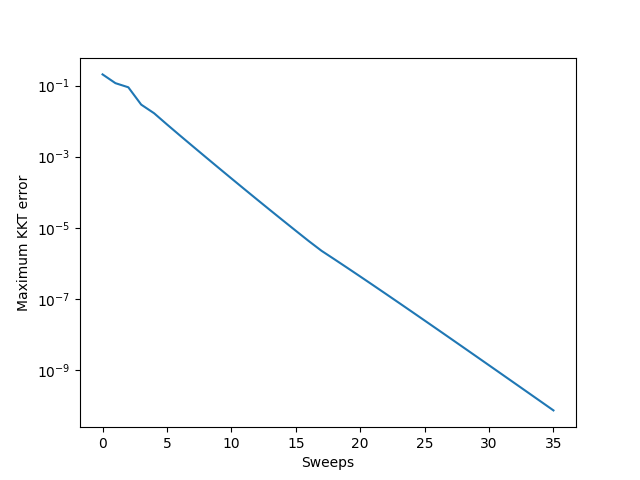

In [5]:
def gaussian_design(rng, n, p, rho):
    """Generate rows with covariance Sigma[j,k] = rho**abs(j-k)."""
    X = rng.standard_normal((n, p))
    for j in range(1, p):
        X[:, j] = rho * X[:, j-1] + np.sqrt(1 - rho**2) * X[:, j]
    return X



rng = np.random.default_rng(112)
Z, _, _ = standardise(gaussian_design(rng, 110, 32, 0.75))
y_check = Z[:, 0] - Z[:, 1] + rng.normal(size=len(Z))
y_check -= y_check.mean()
lam_check = 0.12

Q = np.linalg.qr(Z)[0] * np.sqrt(len(Z))
expected = [soft_threshold(z, lam_check) for z in Q.T @ y_check / len(Q)]
orthogonal_beta, _ = coordinate_descent(Q, y_check, lam_check)
np.testing.assert_allclose(orthogonal_beta, expected, atol=1e-10)
assert len(coordinate_descent(Z, y_check, lambda_max(Z, y_check))[1]) == 1

beta, errors = coordinate_descent(Z, y_check, lam_check, tol=1e-10)
repeated_beta, repeated_errors = coordinate_descent(Z, y_check, lam_check, tol=1e-10)
np.testing.assert_array_equal(beta, repeated_beta)
np.testing.assert_array_equal(errors, repeated_errors)

reference = Lasso(alpha=lam_check, fit_intercept=False, tol=1e-12).fit(Z, y_check)
np.testing.assert_allclose(beta, reference.coef_, atol=1e-7)
np.testing.assert_allclose(Z @ beta, reference.predict(Z), atol=1e-7)
objective_gap = abs(objective(Z, y_check, beta, lam_check)
                    - objective(Z, y_check, reference.coef_, lam_check))
assert objective_gap < 1e-9
print("Largest coefficient gap:", np.max(np.abs(beta - reference.coef_)))
print("Objective gap:", objective_gap)
print("KKT errors:", errors[-1], kkt_error(Z, y_check, reference.coef_, lam_check))

plt.semilogy(errors)
plt.xlabel("Sweeps")
plt.ylabel("Maximum KKT error")
plt.show()

### Duplicate columns

Reverse the columns before fitting, then reverse the coefficient order back. Compare the two predictions in the original column order.

In [6]:
duplicate = Z[:, [0, 0]]
forward, _ = coordinate_descent(duplicate, Z[:, 0], 0.2)
backward, _ = coordinate_descent(duplicate[:, ::-1], Z[:, 0], 0.2)
backward = backward[::-1]
print(forward, backward)
assert not np.allclose(forward, backward)
np.testing.assert_allclose(duplicate @ forward, duplicate @ backward)

[0.8 0. ] [0.  0.8]


## 4. Regularisation path and warm starts

Following Shah §2.2.10 and ESL §3.8.6, solve on a descending geometric grid from $\lambda_{\max}$. Initialise each warm fit with the previous optimum. Cold fits start at zero on the same grid. Compare total sweeps on the same penalty grid. A sweep is one pass through all coordinates. At each penalty verify agreement in fitted values and objective, using numerical tolerances that allow both solves to terminate independently.

Sweeps, cold and warm: 1340 1160


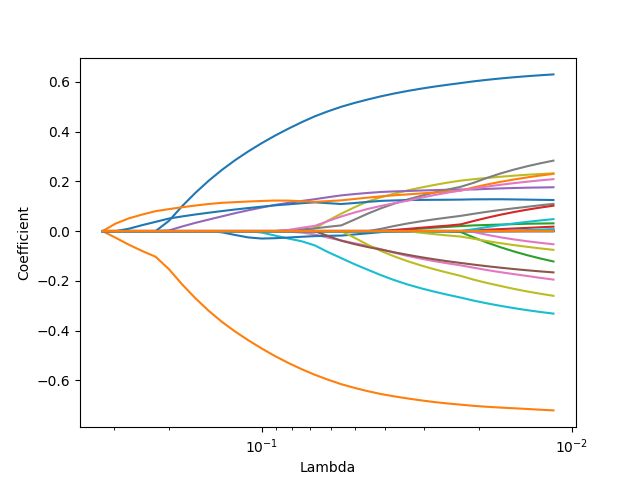

In [7]:
def fit_path(X, y, lambdas, warm=True, tol=1e-8):
    path = []
    sweeps = []
    start = None
    for lam in lambdas:
        beta, errors = coordinate_descent(X, y, lam, start, tol)
        path.append(beta)
        sweeps.append(len(errors) - 1)
        if warm:
            start = beta
    return np.array(path), np.array(sweeps)


penalties = lambda_max(Z, y_check) * np.geomspace(1, 0.035, 35)
warm_path, warm_sweeps = fit_path(Z, y_check, penalties)
cold_path, cold_sweeps = fit_path(Z, y_check, penalties, warm=False)
np.testing.assert_allclose(Z @ warm_path.T, Z @ cold_path.T, atol=2e-6)
for lam, warm_beta, cold_beta in zip(penalties, warm_path, cold_path):
    assert abs(objective(Z, y_check, warm_beta, lam)
               - objective(Z, y_check, cold_beta, lam)) < 1e-9

print("Sweeps, cold and warm:", cold_sweeps.sum(), warm_sweeps.sum())
plt.semilogx(penalties, warm_path)
plt.gca().invert_xaxis()
plt.xlabel("Lambda")
plt.ylabel("Coefficient")
plt.show()

## 5. Held-out generalisation under sparsity and correlation

Generate independent rows $x\sim N_p(0,\Sigma)$ with $\Sigma_{jk}=\rho^{|j-k|}$ and responses $y=2+x^\top\beta^0+\varepsilon$, where $\varepsilon\sim N(0,1)$. Use alternating signs on the first $s$ coordinates and scale each magnitude by $1/\sqrt{s}$ to hold $\|\beta^0\|_2=4$ across sparsity levels. The resulting signal variance $\beta^{0\top}\Sigma\beta^0$ still varies with $\rho$ and $s$.

For each of 16 independent replicates per setting, generate 90 training, 70 validation and 600 test rows. Fit preprocessing on training only. Choose $\lambda$ for Lasso and $\gamma$ for ridge by validation MSE. Keep the fitted training model at the chosen penalty and evaluate it on the untouched test set. OLS uses the minimum-norm solution in standardised coordinates when $p>n$. Ridge solves $(X^\top X/n+\gamma I)b=X^\top y/n$. The mean baseline predicts $\bar y_{\rm train}$. See ESL §§3.2, 3.4.1–3.4.3 for the least squares and shrinkage comparisons.

Report test MSE against observed $y$, test mean-function MSE against $2+X\beta^0$, and $R^2$ relative to the test-set mean. The conditional population excess risk is $R=(\hat a-2)^2+(\hat\beta-\beta^0)^\top\Sigma(\hat\beta-\beta^0)$ in raw coordinates, and prediction risk for noisy future responses is $1+R$. Exact support and $F_1=2TP/(2TP+FP+FN)$ use a $10^{-7}$ threshold for Lasso. Shah §2.2.5 discusses signed selection through the irrepresentable condition. Correlated predictors can yield similar fitted values with different supports, so measure selection separately.

In [8]:
def generalisation_trial(seed, rho, s, p=120):
    rng = np.random.default_rng(seed)
    beta_true = np.zeros(p)
    beta_true[:s] = 4 / np.sqrt(s) * (-1.0) ** np.arange(s)
    raw = gaussian_design(rng, 760, p, rho)
    signal = 2 + raw @ beta_true
    y = signal + rng.standard_normal(len(raw))
    train, valid, test = slice(0, 90), slice(90, 160), slice(160, None)
    X, mean, scale = standardise(raw[train])
    V, T = (raw[valid] - mean) / scale, (raw[test] - mean) / scale
    intercept = y[train].mean()
    yc = y[train] - intercept
    lambdas = lambda_max(X, yc) * np.geomspace(1, 0.025, 22)
    path, _ = fit_path(X, yc, lambdas, tol=2e-7)
    lasso_errors = [np.mean((y[valid] - intercept - V @ beta)**2) for beta in path]
    best_lasso = np.argmin(lasso_errors)

    gammas = np.geomspace(1e-3, 30, 22)
    U, d, VT = np.linalg.svd(X, full_matrices=False)
    ridge_path = np.array([
        VT.T @ (d * (U.T @ yc) / (d**2 + len(X) * gamma))
        for gamma in gammas
    ])
    ridge_errors = [np.mean((y[valid] - intercept - V @ beta)**2) for beta in ridge_path]
    best_ridge = np.argmin(ridge_errors)
    fits = {"Lasso": path[best_lasso], "Ridge": ridge_path[best_ridge],
            "OLS": np.linalg.lstsq(X, yc, rcond=None)[0], "Mean": np.zeros(p)}

    covariance = rho ** np.abs(np.arange(p)[:, None] - np.arange(p))
    results = {}
    for name, coef in fits.items():
        slope = coef / scale
        raw_intercept = intercept - mean @ slope
        delta = slope - beta_true
        pred = T @ coef + intercept
        residual = y[test] - pred
        mse = np.mean(residual**2)
        results[name] = [mse, np.mean((signal[test] - pred)**2),
                         1 - mse / np.var(y[test]),
                         (raw_intercept - 2)**2 + delta @ covariance @ delta]
    selected = np.abs(fits["Lasso"] / scale) > 1e-7
    truth = beta_true != 0
    tp = np.sum(selected & truth)
    selection = [tp / max(selected.sum(), 1), tp / s, 2 * tp / (s + selected.sum()),
                 np.array_equal(selected, truth), selected.sum(), lambdas[best_lasso]]
    return results, selection

### Repeat the experiment

Run each setting with fresh train, validation and test data. Compare models on the same test rows within each replicate. The paired intervals use a $t_{15}$ multiplier. Negative MSE gaps favour Lasso.

rho=0.0, s=4 | mean MSE / signal MSE / R² / population excess risk
  Lasso 1.331 / 0.296 / 0.921 / 0.303
  Ridge 6.856 / 5.835 / 0.594 / 5.903
  OLS   8.161 / 7.151 / 0.517 / 7.168
  Mean  17.069 / 16.039 / -0.008 / 16.136
  Lasso precision / recall / F1 / exact support / size / lambda: [ 0.226  1.     0.356  0.    22.062  0.133]
  Paired test MSE gap vs Ridge: -5.524 ± 0.514
  Paired test MSE gap vs OLS: -6.830 ± 0.743
  Paired test MSE gap vs Mean: -15.738 ± 0.521
rho=0.8, s=4 | mean MSE / signal MSE / R² / population excess risk
  Lasso 1.718 / 0.714 / 0.563 / 0.722
  Ridge 3.484 / 2.483 / 0.112 / 2.532
  OLS   5.827 / 4.821 / -0.489 / 4.919
  Mean  3.984 / 2.979 / -0.014 / 2.985
  Lasso precision / recall / F1 / exact support / size / lambda: [ 0.13   0.984  0.226  0.    33.75   0.072]
  Paired test MSE gap vs Ridge: -1.767 ± 0.171
  Paired test MSE gap vs OLS: -4.109 ± 0.549
  Paired test MSE gap vs Mean: -2.267 ± 0.175
rho=0.0, s=16 | mean MSE / signal MSE / R² / population exces

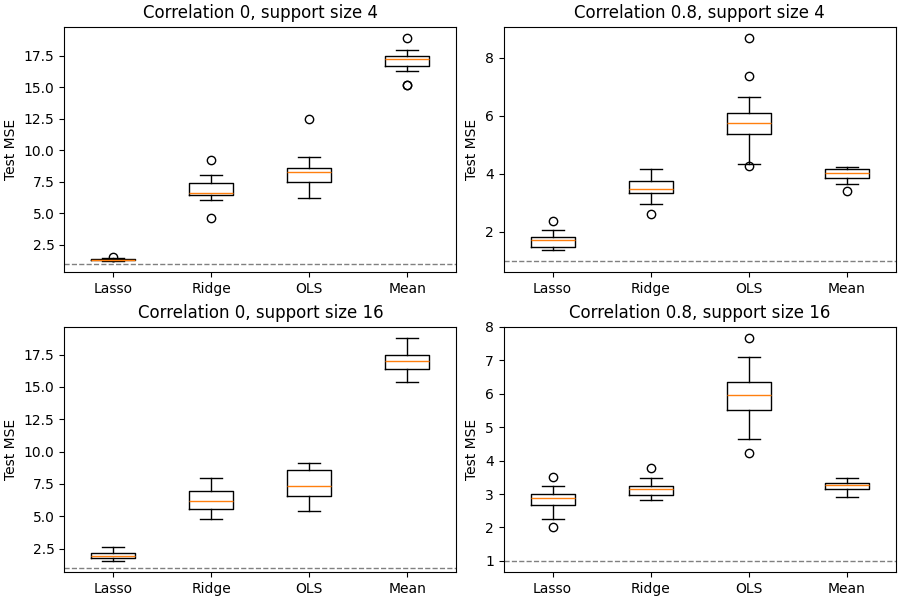

In [9]:
settings = [(0.0, 4), (0.8, 4), (0.0, 16), (0.8, 16)]
names = ["Lasso", "Ridge", "OLS", "Mean"]
generalisation = {}
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")
for i, ((rho, s), ax) in enumerate(zip(settings, axes.flat)):
    trials = [generalisation_trial(6100 + 100*i + k, rho, s) for k in range(16)]
    metrics = np.array([[trial[0][name] for name in names] for trial in trials])
    selection = np.array([trial[1] for trial in trials])
    generalisation[rho, s] = metrics, selection
    print(f"rho={rho:.1f}, s={s} | mean MSE / signal MSE / R² / population excess risk")
    for name, row in zip(names, metrics.mean(axis=0)):
        print(f"  {name:5} " + " / ".join(f"{value:.3f}" for value in row))
    print("  Lasso precision / recall / F1 / exact support / size / lambda:",
          np.round(selection.mean(axis=0), 3))
    for j, name in enumerate(names[1:], start=1):
        gap = metrics[:, 0, 0] - metrics[:, j, 0]
        half_width = 2.131 * gap.std(ddof=1) / np.sqrt(len(gap))
        print(f"  Paired test MSE gap vs {name}: {gap.mean():+.3f} ± {half_width:.3f}")
    ax.boxplot(metrics[:, :, 0], tick_labels=names)
    ax.axhline(1, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=f"Correlation {rho:g}, support size {s}", ylabel="Test MSE")
plt.show()

The paired intervals use a $t_{15}$ multiplier and describe simulation uncertainty in the mean test MSE difference within each setting. Negative gaps favour Lasso. The dashed line marks irreducible noise variance. Compare the test MSE rankings against population excess risk to see how finite test sets affect the rankings. The metrics estimate performance for this synthetic model family and this tuning protocol.

## 6. Lemma 15 and Theorem 11 | fixed-design Monte Carlo

Use centred columns with $\|x_j\|_2^2=n$ and fix $X,\beta^0$. Write $M=\|X^\top\varepsilon/n\|_\infty$. With independent mean-zero $\sigma$-sub-Gaussian errors, Proposition 14 in Shah §2.2.2 gives sub-Gaussian parameter $\sigma\|x_j\|_2/n=\sigma/\sqrt{n}$ for each score. Applying Proposition 12 to both tails and summing over $p$ coordinates gives **Lemma 15**:
$$\Pr(M>\lambda\mid X)\le 2p\exp[-n\lambda^2/(2\sigma^2)]
=2p^{1-A^2/2},\qquad \lambda=A\sigma\sqrt{\log(p)/n}.$$
For Gaussian errors each marginal is exactly normal, giving the additional union bound $2p\,\Phi(-A\sqrt{\log p})$. This uses the Gaussian marginals and allows dependent scores. Rademacher errors $\varepsilon_i=\pm\sigma$ also satisfy Lemma 15 since $\cosh(t\sigma)\le e^{t^2\sigma^2/2}$.

To derive **Theorem 11** (Shah §2.2.1), compare $Q_\lambda(\hat\beta)$ to $Q_\lambda(\beta^0)$. With $\Delta=\hat\beta-\beta^0$ and $D=\|X\Delta\|_2^2/n$, expansion yields
$$D/2\le \varepsilon^\top X\Delta/n+
\lambda(\|\beta^0\|_1-\|\hat\beta\|_1).$$
We fit $y-\bar y\mathbf 1$. Centring the noise leaves the score unchanged since $X^\top\mathbf 1=0$. On $M\le\lambda$, Hölder and $\|\Delta\|_1\le\|\beta^0\|_1+\|\hat\beta\|_1$ give $D\le4\lambda\|\beta^0\|_1$. Thus the same probability bound applies to violations of the prediction inequality.

For two fixed designs with $p>n$, redraw 6,000 independent noise vectors per noise family for Lemma 15 and use the first 160 Gaussian draws per design for Theorem 11. Reuse draws across penalties so the curves are paired. Print Wilson 95% binomial intervals, including when there are zero violations. The bound is clipped at 1 for display. For Theorem 11 also record the 95th percentile of the ratio of prediction error to its upper bound and check the deterministic implication on the proof event.

In [10]:
def binomial_summary(events):
    k, n = int(np.count_nonzero(events)), len(events)
    f = k / n
    z = 1.96
    denom = 1 + z*z/n
    centre = (f + z*z/(2*n)) / denom
    half = z * np.sqrt(f*(1-f)/n + z*z/(4*n*n)) / denom
    return f, max(0, centre - half), min(1, centre + half)


def score_maxima(X, noise):
    return np.abs(noise @ X).max(axis=1) / len(X)

### Draw noise and fit the Lasso

For each penalty, count draws with $M>\lambda$ and fits with $D>4\lambda\|\beta^0\|_1$. The two plots show the event frequencies and the prediction error relative to its bound.

rho=0 | A | Lemma Gaussian / Rademacher fail | Thm 11 fail [Wilson 95%] | bound | p95 ratio
  0.9 | 0.9753 / 0.9942 |   0/160 [0.000, 0.023] | 1.0000 | 0.161
  1.2 | 0.5540 / 0.5810 |   0/160 [0.000, 0.023] | 1.0000 | 0.163
  1.5 | 0.1098 / 0.0895 |   0/160 [0.000, 0.023] | 1.0000 | 0.169
  1.8 | 0.0107 / 0.0043 |   0/160 [0.000, 0.023] | 0.1151 | 0.176
  2.1 | 0.0010 / 0.0000 |   0/160 [0.000, 0.023] | 0.0078 | 0.182
  2.4 | 0.0002 / 0.0000 |   0/160 [0.000, 0.023] | 0.0003 | 0.185
rho=0.8 | A | Lemma Gaussian / Rademacher fail | Thm 11 fail [Wilson 95%] | bound | p95 ratio
  0.9 | 0.8968 / 0.9328 |   0/160 [0.000, 0.023] | 1.0000 | 0.117
  1.2 | 0.4065 / 0.4183 |   0/160 [0.000, 0.023] | 1.0000 | 0.101
  1.5 | 0.0793 / 0.0577 |   0/160 [0.000, 0.023] | 1.0000 | 0.095
  1.8 | 0.0078 / 0.0037 |   0/160 [0.000, 0.023] | 0.1151 | 0.094
  2.1 | 0.0008 / 0.0000 |   0/160 [0.000, 0.023] | 0.0078 | 0.094
  2.4 | 0.0000 / 0.0000 |   0/160 [0.000, 0.023] | 0.0003 | 0.095


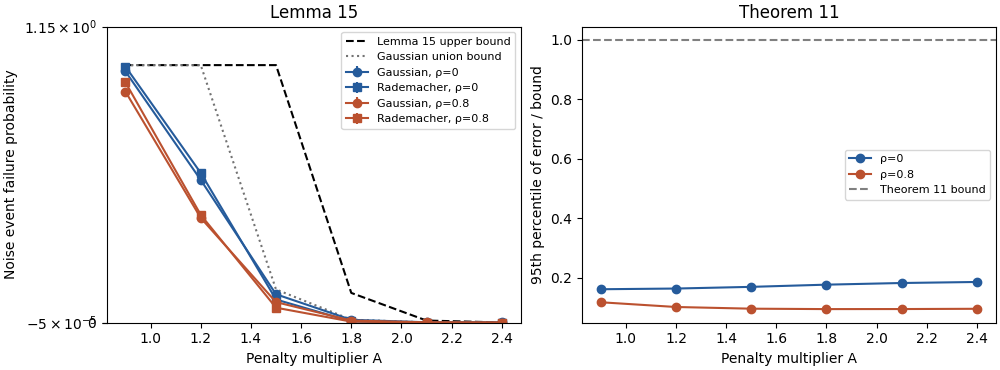

In [11]:
rng = np.random.default_rng(7901)
n, p, sigma = 60, 100, 1.0
A_grid = np.array([0.9, 1.2, 1.5, 1.8, 2.1, 2.4])
tail_bound = np.minimum(1, 2*p**(1-A_grid**2/2))
gaussian_bound = np.minimum(1, [p*erfc(A*sqrt(np.log(p)/2)) for A in A_grid])
beta_true = np.zeros(p)
beta_true[:5] = [1.3, -0.9, 0.8, -0.6, 0.4]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
for rho, colour in [(0.0, "#255b9b"), (0.8, "#bb512f")]:
    X, _, _ = standardise(gaussian_design(rng, n, p, rho))
    np.testing.assert_allclose(np.mean(X**2, axis=0), 1, atol=1e-12)
    np.testing.assert_allclose(X.mean(axis=0), 0, atol=1e-12)
    gaussian = rng.normal(scale=sigma, size=(6000, n))
    rademacher = rng.choice([-sigma, sigma], size=gaussian.shape)
    gaussian_scores = score_maxima(X, gaussian)
    rademacher_scores = score_maxima(X, rademacher)
    signal = X @ beta_true
    for noise_name, scores, marker in [
        ("Gaussian", gaussian_scores, "o"), ("Rademacher", rademacher_scores, "s")
    ]:
        intervals = np.array([binomial_summary(scores > A*sigma*np.sqrt(np.log(p)/n)) for A in A_grid])
        f, low, high = intervals.T
        axes[0].errorbar(A_grid, f, yerr=np.maximum(0, [f-low, high-f]), color=colour,
                         marker=marker, label=f"{noise_name}, ρ={rho:g}")

    ratios_by_A = []
    print(f"rho={rho:g} | A | Lemma Gaussian / Rademacher fail | Thm 11 fail [Wilson 95%] | bound | p95 ratio")
    for A, bound in zip(A_grid, tail_bound):
        lam = A*sigma*np.sqrt(np.log(p)/n)
        ratios = []
        for eps in gaussian[:160]:
            y = signal + eps - eps.mean()
            fitted = coordinate_descent(X, y, lam, tol=1e-8)[0]
            ratios.append(np.mean((X @ (fitted-beta_true))**2) / (4*lam*np.abs(beta_true).sum()))
        ratios = np.array(ratios)
        event = gaussian_scores[:160] <= lam
        assert np.all(ratios[event] <= 1 + 1e-6)
        failures = ratios > 1 + 1e-6
        f, low, high = binomial_summary(failures)
        g = np.mean(gaussian_scores > lam)
        rad = np.mean(rademacher_scores > lam)
        q95 = np.quantile(ratios, 0.95)
        ratios_by_A.append(q95)
        print(f"  {A:3.1f} | {g:.4f} / {rad:.4f} | {failures.sum():3}/160 [{low:.3f}, {high:.3f}] | {bound:.4f} | {q95:.3f}")
    axes[1].plot(A_grid, ratios_by_A, marker="o", color=colour, label=f"ρ={rho:g}")

axes[0].plot(A_grid, tail_bound, "k--", label="Lemma 15 upper bound")
axes[0].plot(A_grid, gaussian_bound, color="0.45", linestyle=":", label="Gaussian union bound")
axes[0].set(xlabel="Penalty multiplier A", ylabel="Noise event failure probability",
            title="Lemma 15", yscale="symlog", ylim=(-0.00005, 1.15))
axes[1].axhline(1, linestyle="--", color="0.5", label="Theorem 11 bound")
axes[1].set(xlabel="Penalty multiplier A", ylabel="95th percentile of error / bound", title="Theorem 11")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

An empirical zero has finite Monte Carlo resolution. The Wilson interval describes uncertainty in a pointwise frequency, and the deterministic implication checks whether any simulated case on the proof event violates the inequality beyond solver tolerance. A penalty can control the noise event and still introduce appreciable shrinkage bias. Read error-to-bound ratios alongside the failure frequencies to judge how informative the bound is.

## 7. Theorem 23 | certify compatibility in a wide design

Let $S=\operatorname{supp}(\beta^0)$, $N=S^c$, $s=|S|$. Shah §2.2.6, Definition 5, defines
$$\phi^2(S)=\inf_{\delta_S\ne0,\;\|\delta_N\|_1\le3\|\delta_S\|_1}
\frac{s\|X\delta\|_2^2}{n\|\delta_S\|_1^2}.$$
On $M\le\lambda/2$, the basic inequality gives $D+\lambda\|\Delta_N\|_1\le3\lambda\|\Delta_S\|_1$ using $\|\beta^0\|_1-\|\hat\beta\|_1\le\|\Delta_S\|_1-\|\Delta_N\|_1$. This places $\Delta$ in the cone. Adding $\lambda\|\Delta_S\|_1$ and using compatibility yields
$$D+\lambda\|\Delta\|_1\le4\lambda\|\Delta_S\|_1\le4\lambda\sqrt{sD}/\phi.$$
The first inequality before adding that term also implies $\sqrt D\le3\lambda\sqrt{s}/\phi$. Substitution gives $D+\lambda\|\Delta\|_1\le12\lambda^2s/\phi^2$. Lemma 15 with multiplier $A/2$ bounds the probability of failure by $2p^{1-A^2/8}$. The proof event at $\lambda_*=A\sigma\sqrt{\log p/n}$ also gives the inequality simultaneously for all $\lambda\ge\lambda_*$.

**Exact construction.** Build orthogonal centred directions $u_1,\dots,u_s$ of norm $\sqrt n$. For each successive pair, use $u_{2j-1}$ and $\rho u_{2j-1}+\sqrt{1-\rho^2}u_{2j}$. Put every nuisance column in the orthogonal complement of these directions and the constant vector. The support Gram has minimum eigenvalue $1-\rho$, so the ratio is at least $1-\rho$ by Cauchy–Schwarz and the orthogonal decomposition. Equality holds for $\delta_N=0$ with equal magnitudes and opposite signs in each pair, so $\phi^2=1-\rho$ even though $p>n$. At $\rho=1$ that same vector is a cone null vector, so $\phi^2=0$.

Keep $p=400$, use three sample sizes, two support sizes, and two values of $\rho$. Draw 40 Gaussian errors per design and set $A=3.5$. Report event and inequality failures, and plot mean joint error against the reference scale $\lambda^2s/\phi^2$ to examine how well the fast-rate scale tracks changes in the design. The sample sizes and fixed signal magnitude allow shrinkage bias to matter in the smallest designs.

In [12]:
def compatible_design(rng, n, p, s, rho):
    directions = rng.standard_normal((n, s))
    directions -= directions.mean(axis=0)
    U = np.linalg.qr(directions, mode="reduced")[0]
    active = U.copy()
    active[:, 1::2] = rho*U[:, ::2] + np.sqrt(1-rho*rho)*U[:, 1::2]
    noise_columns = rng.standard_normal((n, p-s))
    noise_columns -= noise_columns.mean(axis=0)
    noise_columns -= U @ (U.T @ noise_columns)
    X = np.column_stack((np.sqrt(n)*active, standardise(noise_columns)[0]))
    np.testing.assert_allclose(X.mean(axis=0), 0, atol=1e-12)
    np.testing.assert_allclose(np.mean(X**2, axis=0), 1, atol=1e-12)
    np.testing.assert_allclose(X[:, :s].T @ X[:, s:] / n, 0, atol=1e-12)
    smallest = np.linalg.eigvalsh(X[:, :s].T @ X[:, :s] / n)[0]
    np.testing.assert_allclose(smallest, 1-rho, atol=1e-12)
    witness = (-1.0)**np.arange(s)
    ratio = s*np.mean((X[:, :s] @ witness)**2) / np.abs(witness).sum()**2
    np.testing.assert_allclose(ratio, 1-rho, atol=1e-12)
    return X

### Compare certified designs

Fit Lasso for each noise draw and compare the joint error with $12\lambda^2s/\phi^2$. The last example makes an active pair identical, giving an explicit cone direction with zero prediction norm.

Theorem 23 failure upper bound: 0.0829
  n   s  rho  phi² | event misses | bound violations [Wilson 95%] | mean error/bound
 64   2 0.00  1.00 |  0/40 |  0/40 [0.000, 0.088] | 0.173
128   2 0.00  1.00 |  0/40 |  0/40 [0.000, 0.088] | 0.161
256   2 0.00  1.00 |  0/40 |  0/40 [0.000, 0.088] | 0.167
 64   6 0.00  1.00 |  1/40 |  0/40 [0.000, 0.088] | 0.168
128   6 0.00  1.00 |  0/40 |  0/40 [0.000, 0.088] | 0.168
256   6 0.00  1.00 |  1/40 |  0/40 [0.000, 0.088] | 0.168
 64   2 0.65  0.35 |  1/40 |  0/40 [0.000, 0.088] | 0.166
128   2 0.65  0.35 |  0/40 |  0/40 [0.000, 0.088] | 0.166
256   2 0.65  0.35 |  0/40 |  0/40 [0.000, 0.088] | 0.165
 64   6 0.65  0.35 |  1/40 |  0/40 [0.000, 0.088] | 0.166
128   6 0.65  0.35 |  0/40 |  0/40 [0.000, 0.088] | 0.166
256   6 0.65  0.35 |  0/40 |  0/40 [0.000, 0.088] | 0.166
Duplicated active pair: phi² = 0, so Theorem 23 supplies no finite bound.


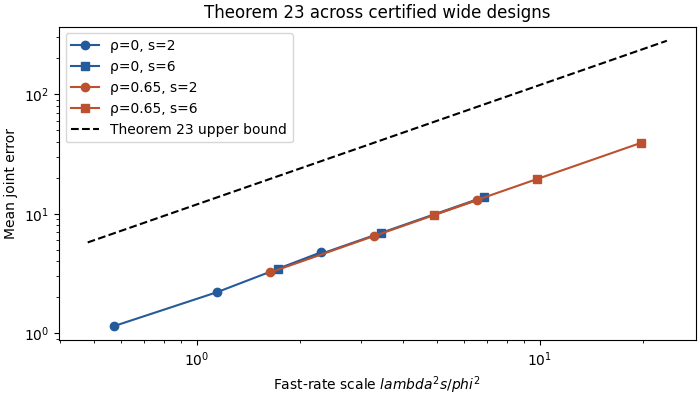

In [13]:
rng = np.random.default_rng(9084)
A, p, sigma, repetitions = 3.5, 400, 1.0, 40
certificate = min(1, 2*p**(1-A*A/8))
print(f"Theorem 23 failure upper bound: {certificate:.4f}")
print("  n   s  rho  phi² | event misses | bound violations [Wilson 95%] | mean error/bound")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for rho, colour in [(0.0, "#255b9b"), (0.65, "#bb512f")]:
    for s, marker in [(2, "o"), (6, "s")]:
        scales, means = [], []
        for n in [64, 128, 256]:
            X = compatible_design(rng, n, p, s, rho)
            phi2 = 1-rho
            beta_true = np.zeros(p)
            beta_true[:s] = 4 * (-1.0)**np.arange(s)
            lam = A*sigma*np.sqrt(np.log(p)/n)
            scale = lam**2*s/phi2
            errors = rng.normal(scale=sigma, size=(repetitions, n))
            event = score_maxima(X, errors) <= lam/2
            lhs = []
            for eps in errors:
                y = X @ beta_true + eps - eps.mean()
                beta = coordinate_descent(X, y, lam, tol=1e-8)[0]
                delta = beta-beta_true
                lhs.append(np.mean((X @ delta)**2) + lam*np.abs(delta).sum())
            lhs = np.array(lhs)
            ratio = lhs / (12*scale)
            assert np.all(ratio[event] <= 1 + 1e-6)
            fails = ratio > 1 + 1e-6
            _, low, high = binomial_summary(fails)
            print(f"{n:3} {s:3} {rho:4.2f} {phi2:5.2f} | {np.sum(~event):2}/{repetitions} | "
                  f"{fails.sum():2}/{repetitions} [{low:.3f}, {high:.3f}] | {ratio.mean():.3f}")
            scales.append(scale)
            means.append(lhs.mean())
        ax.loglog(scales, means, marker=marker, color=colour, label=f"ρ={rho:g}, s={s}")
x_ref = np.array(ax.get_xlim())
ax.loglog(x_ref, 12*x_ref, "k--", label="Theorem 23 upper bound")
ax.set(xlabel=r"Fast-rate scale $lambda^2s/phi^2$", ylabel="Mean joint error",
       title="Theorem 23 across certified wide designs")
ax.legend()
plt.show()

X_bad = compatible_design(rng, 64, p, 2, 1.0)
np.testing.assert_allclose(X_bad[:, 0] - X_bad[:, 1], 0, atol=1e-12)
print("Duplicated active pair: phi² = 0, so Theorem 23 supplies no finite bound.")

## 8. Interpretation for the paper

### Results from the saved run

The numerical checks report the coefficient gap from scikit-learn and the sweep counts for the two initialisation strategies.

Lasso had the lowest mean test MSE in all four settings. Its advantage over ridge was largest with independent predictors and four signals (5.52 MSE units) and smallest with correlated predictors and 16 signals (0.33 units). Exact support recovery was zero across the 64 validation-tuned fits, and mean recall fell to 0.57 in the correlated 16-signal setting.

At A = 1.8 the Gaussian score-event failure rates were 1.07% and 0.78% across the two fixed designs, versus the Lemma 15 upper bound of 11.51%. Theorem 11 had zero observed violations and its largest 95th-percentile error-to-bound ratio was about 0.185. Theorem 23 also had zero observed violations, including the four draws outside its sufficient noise event. Its mean joint error was about 16% to 17% of the upper bound across the certified designs.

- **Optimisation.** Use the KKT residual, objective agreement and the analytic orthogonal check as solver evidence. Report warm-start savings in sweeps for the chosen grid. The duplicate-column example shows that reproducibility of fitted values can coexist with multiple coefficient vectors.
- **Generalisation.** Use the paired held-out MSE gaps to compare Lasso, ridge and OLS across the four settings. Report precision, recall and exact support alongside prediction. Adjacent alternating signals partially cancel when correlation is high, so correlation and effective signal strength both contribute to the observed differences.
- **Probability bounds.** Compare event frequencies to the union bounds and use error-to-bound ratios to quantify slack. Finite Monte Carlo samples have limited resolution for rare events. Theorems 11 and 23 concern prediction at the training design and use a penalty calibrated with known $\sigma$. The held-out experiment tunes its penalty using independent validation data.
- **Compatibility.** The exact calculation makes Theorem 23 applicable even though the full Gram matrix is singular. The fast-rate plot varies $n$, $s$ and compatibility in controlled examples. With fixed $p$ and $s$ within each curve, $\lambda^2s/\phi^2$ decreases as $1/n$. The few sample sizes illustrate this scale without estimating a high-dimensional asymptotic exponent.

## References

1. Rajen D. Shah, *Modern Statistical Methods*, supplied file **Modern Statistical Methods R.Shah.pdf**, Chapter 2. Theorem 11 is in §2.2.1, printed p. 22. Lemma 15 is in §2.2.2, p. 24. KKT and uniqueness are in §§2.2.3–2.2.4. Definition 5 and Theorem 23 are in §2.2.6, pp. 29–31. Computation is in §2.2.10, pp. 35–36. The numbering and constant 12 follow the supplied edition. [Cambridge copy with matching numbering](https://www.dpmms.cam.ac.uk/~rds37/teaching/modern_stat_methods/notes.pdf).
2. Trevor Hastie, Robert Tibshirani and Jerome Friedman (2009), *The Elements of Statistical Learning*, 2nd ed., supplied file **The Elements of Statistical Learning.pdf**, Chapter 3, §§3.2, 3.4.1–3.4.3 and 3.8.6. [Publisher chapter](https://doi.org/10.1007/978-0-387-84858-7_3).